In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
import warnings
warnings.filterwarnings("ignore")

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/suicide-rates-overview-1985-to-2016/master.csv


# SUICIDE RATES OVERVIEW(1985-2016) EXPLORATORY ANALYSIS

This data set consists of details about the suicide rates of all the countries in the world.It consists of 12 columns namely country,sex,population,age,year and so on. As the first step let's load the dataset and go through the first 5 columns to get an idea about the data set.In this kernel, I have analysed this dataset to find top insights and findings.

In [2]:
import pandas as pd
df=pd.read_csv("/kaggle/input/suicide-rates-overview-1985-to-2016/master.csv")
print("COLUMNS              NULL-VALUES\n")
print(df.isnull().sum())
df.head()


COLUMNS              NULL-VALUES

country                   0
year                      0
sex                       0
age                       0
suicides_no               0
population                0
suicides/100k pop         0
country-year              0
HDI for year          19456
 gdp_for_year ($)         0
gdp_per_capita ($)        0
generation                0
dtype: int64


,country,year,sex,age,suicides_no,population,suicides/100k pop,country-year,HDI for year,gdp_for_year ($),gdp_per_capita ($),generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,NaN,"2,156,624,900",796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,NaN,"2,156,624,900",796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,NaN,"2,156,624,900",796,Generation X
3,Albania,1987,male,75+ years,1,21800,4.59,Albania1987,NaN,"2,156,624,900",796,G.I. Generation
4,Albania,1987,male,25-34 years,9,274300,3.28,Albania1987,NaN,"2,156,624,900",796,Boomers


We can infer from the above cell that except for HDI all other columns do not have null values. So let's drop the HDI column to get a clean dataset ready for analysis.

In [3]:
df.drop(columns=["HDI for year"],inplace=True)
df.head()

,country,year,sex,age,suicides_no,population,suicides/100k pop,country-year,gdp_for_year ($),gdp_per_capita ($),generation
0,Albania,1987,male,15-24 years,21,312900,6.71,Albania1987,"2,156,624,900",796,Generation X
1,Albania,1987,male,35-54 years,16,308000,5.19,Albania1987,"2,156,624,900",796,Silent
2,Albania,1987,female,15-24 years,14,289700,4.83,Albania1987,"2,156,624,900",796,Generation X
3,Albania,1987,male,75+ years,1,21800,4.59,Albania1987,"2,156,624,900",796,G.I. Generation
4,Albania,1987,male,25-34 years,9,274300,3.28,Albania1987,"2,156,624,900",796,Boomers


# SUICIDE RATES AROUND THE WORLD

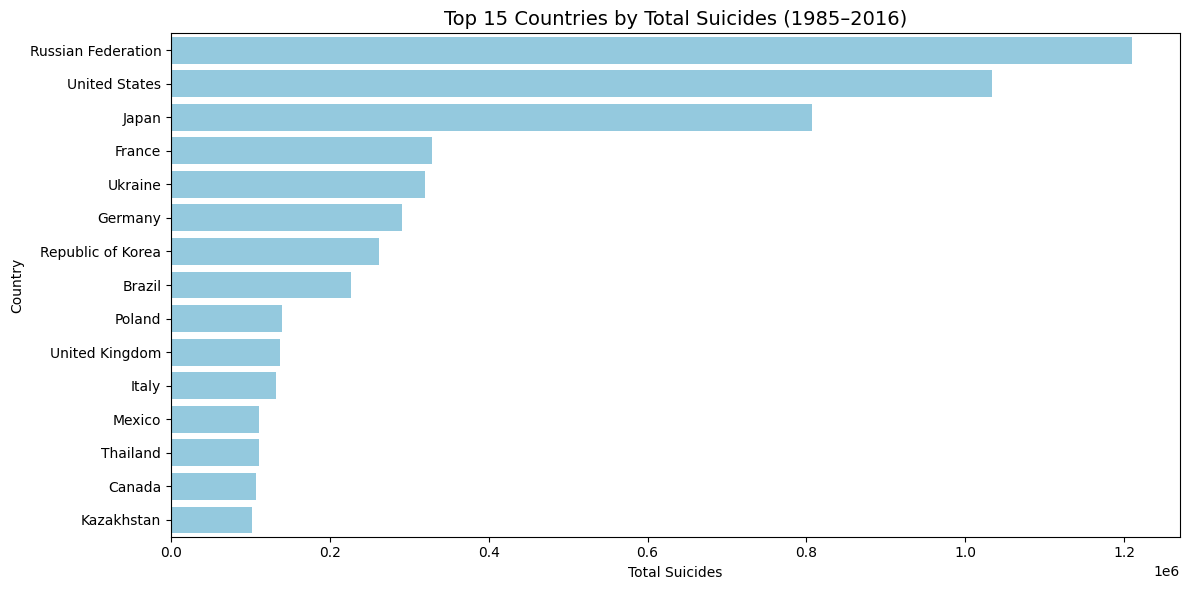

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 1: Prepare the data
total_deaths = df.groupby("country")["suicides_no"].sum().sort_values(ascending=False).head(15).reset_index()

# Step 2: Create the bar plot
plt.figure(figsize=(12, 6))
sns.barplot(data=total_deaths, x="suicides_no", y="country",color="skyblue" )

# Customize the plot
plt.title("Top 15 Countries by Total Suicides (1985–2016)", fontsize=14)
plt.xlabel("Total Suicides")
plt.ylabel("Country")
plt.tight_layout()

# Show plot
plt.show()


We can hence infer from the above cell that Russian Federation has the highest number of suicides in the world followed by United States and Japan.



# YEAR WISE SUICIDE RATE

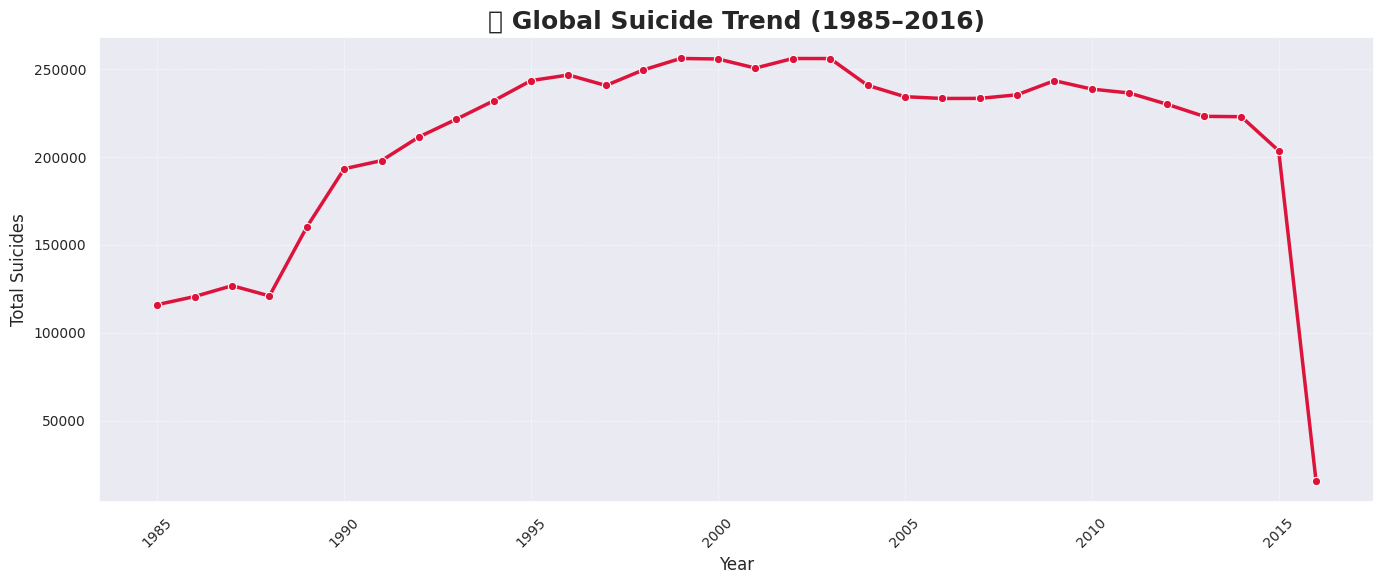

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set theme
sns.set_theme(style="darkgrid")

# Group and reset index
suicide = df.groupby("year")["suicides_no"].sum().reset_index()

# Create the figure
plt.figure(figsize=(14, 6))

# Lineplot with better styling
sns.lineplot(
    data=suicide,
    x="year",
    y="suicides_no",
    marker="o",             # Add dots on line
    linewidth=2.5,          # Thicker line
    color="crimson"         # Nicer color
)

# Add labels and title with styling
plt.title("📉 Global Suicide Trend (1985–2016)", fontsize=18, fontweight='bold')
plt.xlabel("Year", fontsize=12)
plt.ylabel("Total Suicides", fontsize=12)

# Tweak ticks
plt.xticks(fontsize=10, rotation=45)
plt.yticks(fontsize=10)

# Optional: Add a light grid
plt.grid(visible=True, which='major', linestyle='--', linewidth=0.5, alpha=0.7)

# Tight layout
plt.tight_layout()

# Show plot
plt.show()


There was a steep rise in suicide rates from 1985 to 1990 and from then on the growth has been steady.

# GENDER WISE SUICIDE RATE


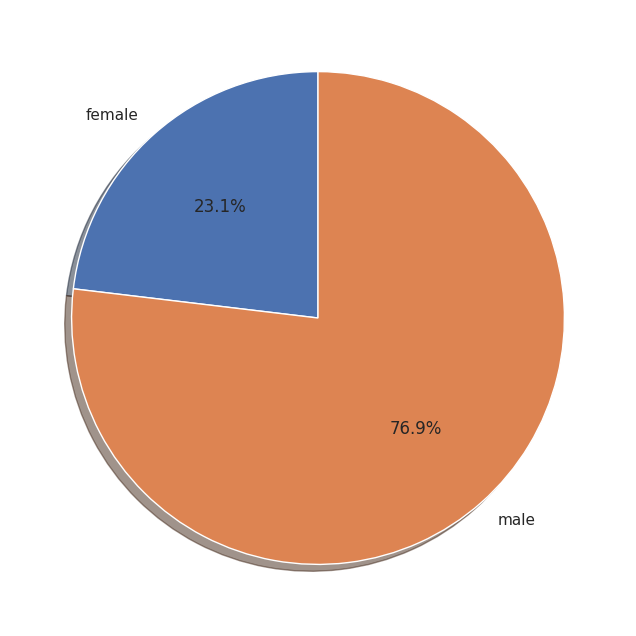

In [6]:
import matplotlib.pyplot as plt


sizes1 = df.groupby("sex")["suicides_no"].sum()
sizes=sizes1.values
labels=sizes1.index
fig, ax = plt.subplots(figsize=(8, 8))


ax.pie(sizes, labels=labels, autopct='%1.1f%%',shadow={'ox': -0.04, 'edgecolor': 'none', 'shade': 0.9}, startangle=90)
plt.show()

The suicide rate of male is much higher than that of females around the world.

# AGE WISE SUICIDE RATE

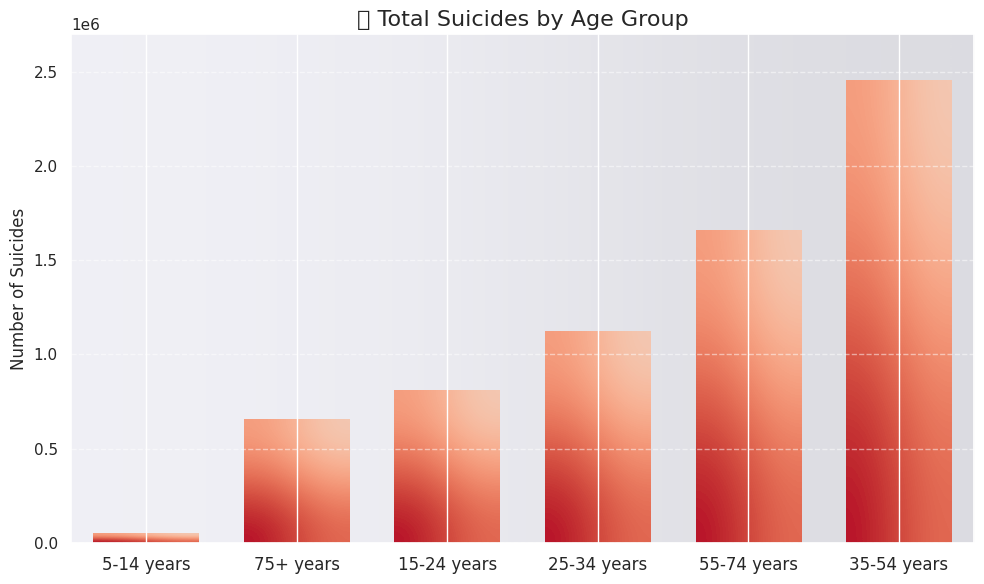

In [7]:
import matplotlib.pyplot as plt
import numpy as np

# Prepare your actual data
data = df.groupby("age")["suicides_no"].sum().sort_values()
x_labels = data.index               # Age groups
y = data.values                     # Suicide counts
x = np.arange(len(x_labels)) + 0.15

# Gradient functions
def gradient_image(ax, direction=0.3, cmap_range=(0, 1), **kwargs):
    phi = direction * np.pi / 2
    v = np.array([np.cos(phi), np.sin(phi)])
    X = np.array([[v @ [1, 0], v @ [1, 1]],
                  [v @ [0, 0], v @ [0, 1]]])
    a, b = cmap_range
    X = a + (b - a) / X.max() * X
    im = ax.imshow(X, interpolation='bicubic', clim=(0, 1),
                   aspect='auto', **kwargs)
    return im

def gradient_bar(ax, x, y, width=0.5, bottom=0):
    for left, top in zip(x, y):
        right = left + width
        gradient_image(ax, extent=(left, right, bottom, top),
                       cmap=plt.cm.coolwarm_r, cmap_range=(0.0, 0.4))

# Plotting
fig, ax = plt.subplots(figsize=(10, 6))
ax.set(xlim=(0, len(x_labels)), ylim=(0, y.max() * 1.1))

# Optional background gradient
gradient_image(ax, direction=1, extent=(0, 1, 0, 1), transform=ax.transAxes,
               cmap=plt.cm.Greys, cmap_range=(0.0, 0.4), alpha=0.3)

# Add gradient bars
gradient_bar(ax, x, y, width=0.7)

# Set ticks and labels
ax.set_xticks(x + 0.35)
ax.set_xticklabels(x_labels, fontsize=12)
plt.title("🧠 Total Suicides by Age Group", fontsize=16)
plt.ylabel("Number of Suicides")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


We can infer from the above cell that the age group of 35-54 years has the highest number of suicide rates and are more vulnerable.

# GENERATION WISE SUICIDE RATE

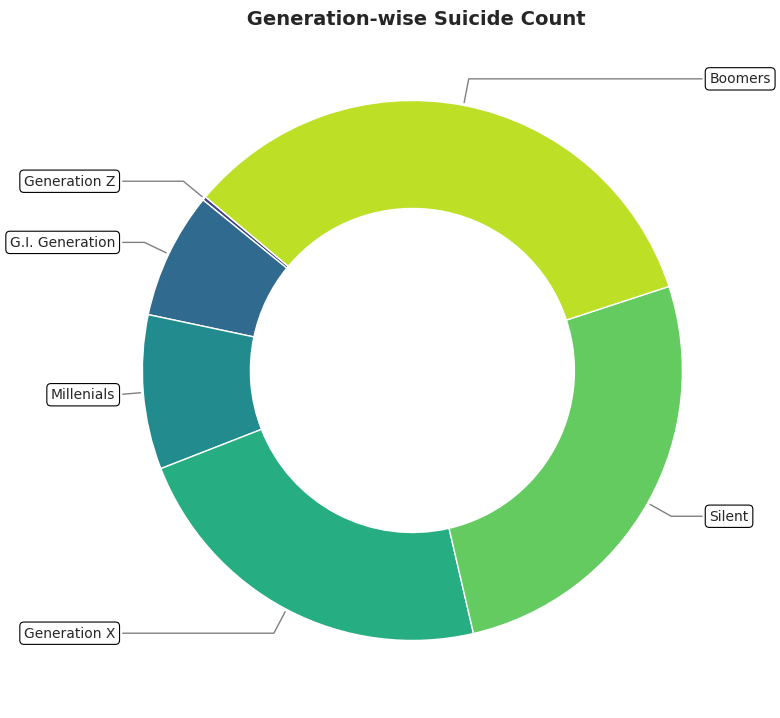

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Data preparation
fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(aspect="equal"))

sui = df.groupby("generation")["suicides_no"].sum().sort_values()
recipe = sui.index
data = sui.values

# Donut-style pie chart
wedges, texts = ax.pie(
    data,
    wedgeprops=dict(width=0.4, edgecolor='w'),
    startangle=140,
    colors=plt.cm.viridis(np.linspace(0.2, 0.9, len(data)))
)

# Annotation settings
bbox_props = dict(boxstyle="round,pad=0.3", fc="white", ec="black", lw=0.8)
kw = dict(arrowprops=dict(arrowstyle="-", color="gray"),
          bbox=bbox_props, zorder=0, va="center", fontsize=10)

# Annotate each wedge
for i, p in enumerate(wedges):
    ang = (p.theta2 - p.theta1) / 2. + p.theta1
    x = np.cos(np.deg2rad(ang))
    y = np.sin(np.deg2rad(ang))
    horizontalalignment = "left" if x > 0 else "right"
    connectionstyle = f"angle,angleA=0,angleB={ang}"
    kw["arrowprops"].update({"connectionstyle": connectionstyle})
    
    ax.annotate(recipe[i], xy=(x, y), xytext=(1.1*np.sign(x), 1.1*y),
                horizontalalignment=horizontalalignment, **kw)

# Title
ax.set_title(" Generation-wise Suicide Count", fontsize=14, weight='bold')

plt.tight_layout()
plt.show()


We can infer from the above that Boomers generation have the highest no. of suicide rates.

# CONCLUSION

The analysis of global suicide trends from 1985 to 2016 reveals deeply concerning patterns across age, gender, geography, and generation:

🔹 Most Affected Age Group: Individuals aged 35 to 54 years are the most vulnerable, possibly due to mid-life stressors such as career pressure, financial burdens, and societal responsibilities. This age group sits at the intersection of personal and professional strain.

🔹 Gender Disparity: A stark imbalance is evident—76.9% of suicide cases involve males. Cultural expectations, emotional suppression, and limited help-seeking behavior among men may contribute to this crisis.

🔹 Geographic Hotspot: The Russian Federation reports the highest number of suicides in the dataset. This could be attributed to factors like economic instability, substance abuse, limited mental health infrastructure, and cultural stigma around psychological support.

🔹 Generational Trends: The 'Boomer' and 'Silent Generation' show the highest suicide counts. These older generations may experience social isolation, declining physical health, or generational resistance to seeking mental health care—making them particularly at risk.

By recognizing these patterns, we can work toward a world where mental health is treated with the same seriousness as physical health—ensuring that support reaches the right people at the right time.